## Setup and data loading

In [1]:
import time
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC
from sklearn.datasets import make_moons
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

DATA_PATH = Path("data_banknote_authentication.txt")
DATA_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/00267/data_banknote_authentication.txt"

if not DATA_PATH.exists():
    try:
        urllib.request.urlretrieve(DATA_URL, DATA_PATH)
        print("Downloaded dataset:", DATA_PATH.resolve())
    except Exception as exc:
        raise RuntimeError(
            "Dataset download failed. Download data_banknote_authentication.txt "
            "from the UCI Banknote Authentication dataset and place it beside this notebook."
        ) from exc

columns = ["variance", "skewness", "curtosis", "entropy", "class"]
df = pd.read_csv(DATA_PATH, header=None, names=columns)
print("Shape:", df.shape)
display(df.head())
display(df.describe())
print("Class distribution:\n", df["class"].value_counts().sort_index())
print("Missing values:\n", df.isna().sum())

Downloaded dataset: C:\Users\daksh\OneDrive\Documents\DAU\SEM 1\Machine Learning\202618033_DS605\202618033_Lab_8\data_banknote_authentication.txt
Shape: (1372, 5)


,variance,skewness,curtosis,entropy,class
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


,variance,skewness,curtosis,entropy,class
count,1372.000000,1372.000000,1372.000000,1372.000000,1372.000000
mean,0.433735,1.922353,1.397627,-1.191657,0.444606
std,2.842763,5.869047,4.310030,2.101013,0.497103
min,-7.042100,-13.773100,-5.286100,-8.548200,0.000000
25%,-1.773000,-1.708200,-1.574975,-2.413450,0.000000
50%,0.496180,2.319650,0.616630,-0.586650,0.000000
75%,2.821475,6.814625,3.179250,0.394810,1.000000
max,6.824800,12.951600,17.927400,2.449500,1.000000


Class distribution:
 class
0    762
1    610
Name: count, dtype: int64
Missing values:
 variance    0
skewness    0
curtosis    0
entropy     0
class       0
dtype: int64


## Shared train/test split
The same stratified split is used for the banknote experiments. The first two features (`variance`, `skewness`) are used for 2D plots; all four features are used in Part D.

In [2]:
FEATURES = ["variance", "skewness", "curtosis", "entropy"]
X = df[FEATURES].to_numpy(dtype=float)
y = df["class"].to_numpy(dtype=int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)
X_train_2d, X_test_2d = X_train[:, :2], X_test[:, :2]
print("Train shape:", X_train.shape, "| Test shape:", X_test.shape)

Train shape: (1029, 4) | Test shape: (343, 4)


# Part A — Decision Tree from Scratch

The tree evaluates thresholds between unique sorted feature values, chooses the split with the greatest impurity reduction, and recursively grows child nodes. Stopping rules include pure nodes, maximum depth, minimum samples to split, minimum samples per leaf, and negligible gain.

In [3]:
def gini_impurity(labels):
    """Return Gini impurity for a label vector."""
    if len(labels) == 0:
        return 0.0
    _, counts = np.unique(labels, return_counts=True)
    p = counts / counts.sum()
    return float(1 - np.sum(p ** 2))


def entropy_impurity(labels):
    """Return Shannon entropy in bits."""
    if len(labels) == 0:
        return 0.0
    _, counts = np.unique(labels, return_counts=True)
    p = counts / counts.sum()
    return float(-np.sum(p * np.log2(p)))


def majority_class(labels):
    values, counts = np.unique(labels, return_counts=True)
    return values[np.argmax(counts)]


class ManualDecisionTree:
    """CART-style decision tree for numeric features, implemented with NumPy."""

    def __init__(self, criterion="gini", max_depth=5, min_samples_split=2,
                 min_samples_leaf=1, min_impurity_decrease=1e-12):
        if criterion not in {"gini", "entropy"}:
            raise ValueError("criterion must be 'gini' or 'entropy'")
        self.criterion = criterion
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        self.min_impurity_decrease = min_impurity_decrease
        self.root_ = None
        self.n_features_in_ = None

    def _impurity(self, labels):
        return gini_impurity(labels) if self.criterion == "gini" else entropy_impurity(labels)

    def _best_split(self, X_node, y_node):
        n = len(y_node)
        parent = self._impurity(y_node)
        best_gain, best_feature, best_threshold = 0.0, None, None

        for feature in range(X_node.shape[1]):
            values = np.unique(X_node[:, feature])
            if len(values) < 2:
                continue
            thresholds = (values[:-1] + values[1:]) / 2.0
            col = X_node[:, feature]

            for threshold in thresholds:
                left = col <= threshold
                right = ~left
                n_left, n_right = int(left.sum()), int(right.sum())
                if n_left < self.min_samples_leaf or n_right < self.min_samples_leaf:
                    continue
                child_impurity = (
                    n_left / n * self._impurity(y_node[left])
                    + n_right / n * self._impurity(y_node[right])
                )
                gain = parent - child_impurity
                if gain > best_gain:
                    best_gain, best_feature, best_threshold = gain, feature, float(threshold)

        return best_feature, best_threshold, best_gain

    def _build(self, X_node, y_node, depth):
        node = {
            "prediction": int(majority_class(y_node)),
            "samples": int(len(y_node)),
            "impurity": self._impurity(y_node),
            "feature": None, "threshold": None, "left": None, "right": None,
            "depth": int(depth)
        }
        pure = len(np.unique(y_node)) == 1
        depth_limit = self.max_depth is not None and depth >= self.max_depth
        too_few = len(y_node) < self.min_samples_split
        if pure or depth_limit or too_few:
            return node

        feature, threshold, gain = self._best_split(X_node, y_node)
        if feature is None or gain <= self.min_impurity_decrease:
            return node

        left = X_node[:, feature] <= threshold
        node.update(feature=int(feature), threshold=float(threshold), gain=float(gain))
        node["left"] = self._build(X_node[left], y_node[left], depth + 1)
        node["right"] = self._build(X_node[~left], y_node[~left], depth + 1)
        return node

    def fit(self, X_values, y_values):
        X_values = np.asarray(X_values, dtype=float)
        y_values = np.asarray(y_values)
        if X_values.ndim != 2 or len(X_values) != len(y_values):
            raise ValueError("X must be 2D and have the same number of rows as y")
        self.n_features_in_ = X_values.shape[1]
        self.root_ = self._build(X_values, y_values, depth=0)
        return self

    def _predict_one(self, row):
        node = self.root_
        while node["feature"] is not None:
            node = node["left"] if row[node["feature"]] <= node["threshold"] else node["right"]
        return node["prediction"]

    def predict(self, X_values):
        if self.root_ is None:
            raise RuntimeError("Call fit before predict.")
        return np.array([self._predict_one(row) for row in np.asarray(X_values, dtype=float)])

    def print_tree(self, feature_names, node=None, prefix=""):
        """Print readable split rules for the trained tree."""
        if node is None:
            node = self.root_
        if node["feature"] is None:
            print(f"{prefix}Leaf: class={node['prediction']}, n={node['samples']}, impurity={node['impurity']:.3f}")
            return
        name = feature_names[node["feature"]]
        print(f"{prefix}{name} <= {node['threshold']:.5f}? (n={node['samples']}, impurity={node['impurity']:.3f})")
        print(prefix + "  [True] ")
        self.print_tree(feature_names, node["left"], prefix + "    ")
        print(prefix + "  [False]")
        self.print_tree(feature_names, node["right"], prefix + "    ")


print("Example Gini:", gini_impurity(np.array([0, 0, 1, 1])))
print("Example entropy:", entropy_impurity(np.array([0, 0, 1, 1])))

Example Gini: 0.5
Example entropy: 1.0


### A1. Fit manual and Scikit-learn trees using two features

In [4]:
manual_tree_2d = ManualDecisionTree(
    criterion="gini", max_depth=5, min_samples_split=2, min_samples_leaf=2
).fit(X_train_2d, y_train)

sk_tree_2d = DecisionTreeClassifier(
    criterion="gini", max_depth=5, min_samples_leaf=2, random_state=RANDOM_STATE
).fit(X_train_2d, y_train)

print("Manual tree 2D accuracy:", accuracy_score(y_test, manual_tree_2d.predict(X_test_2d)))
print("Scikit-learn tree 2D accuracy:", accuracy_score(y_test, sk_tree_2d.predict(X_test_2d)))
print("\nManual tree split rules:")
manual_tree_2d.print_tree(["variance", "skewness"])

Manual tree 2D accuracy: 0.9271137026239067
Scikit-learn tree 2D accuracy: 0.9271137026239067

Manual tree split rules:
variance <= 0.76510? (n=1029, impurity=0.494)
  [True] 
    skewness <= 5.16080? (n=555, impurity=0.357)
      [True] 
        variance <= 0.32016? (n=436, impurity=0.155)
          [True] 
            variance <= -0.45857? (n=390, impurity=0.093)
              [True] 
                skewness <= 0.05483? (n=328, impurity=0.053)
                  [True] 
                    Leaf: class=1, n=193, impurity=0.000
                  [False]
                    Leaf: class=1, n=135, impurity=0.124
              [False]
                skewness <= -0.17590? (n=62, impurity=0.271)
                  [True] 
                    Leaf: class=1, n=24, impurity=0.486
                  [False]
                    Leaf: class=1, n=38, impurity=0.000
          [False]
            skewness <= 0.98186? (n=46, impurity=0.476)
              [True] 
                skewness <= 0.68182? (n=

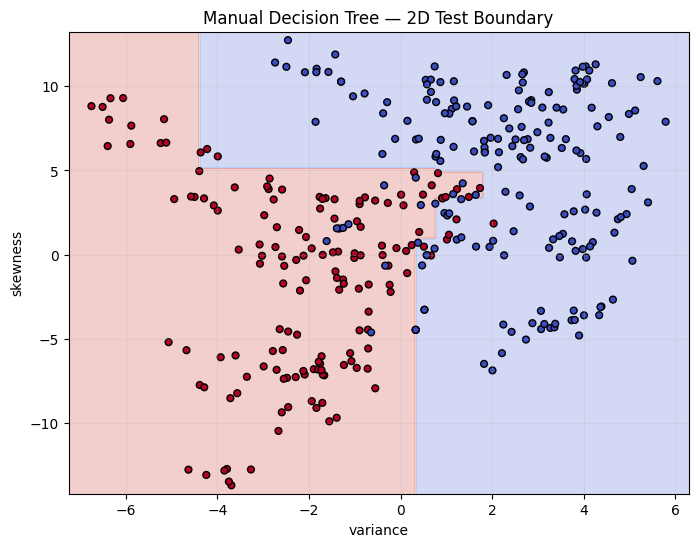

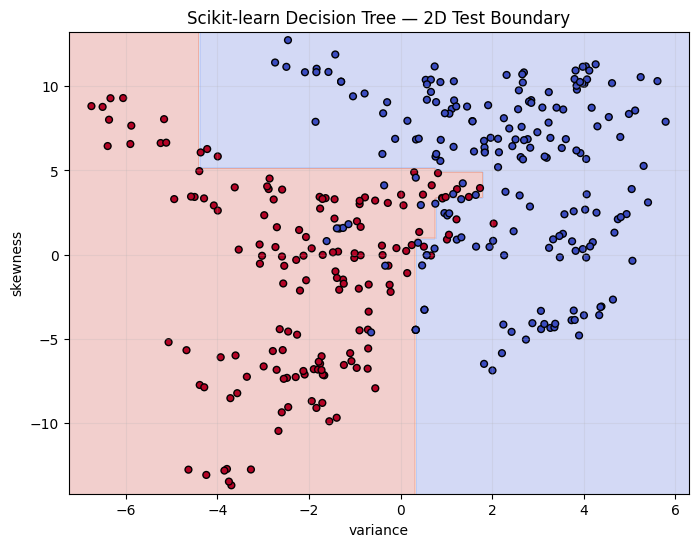

In [5]:
def plot_2d_boundary(model, X_values, y_values, title, feature_names=("variance", "skewness"), grid_points=250):
    """Plot predicted regions and data points for a two-feature model."""
    x_min, x_max = X_values[:, 0].min() - 0.5, X_values[:, 0].max() + 0.5
    y_min, y_max = X_values[:, 1].min() - 0.5, X_values[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, grid_points),
                         np.linspace(y_min, y_max, grid_points))
    zz = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    plt.figure(figsize=(8, 6))
    plt.contourf(xx, yy, zz, alpha=0.25, cmap="coolwarm")
    plt.scatter(X_values[:, 0], X_values[:, 1], c=y_values, cmap="coolwarm",
                edgecolor="k", s=24)
    plt.xlabel(feature_names[0])
    plt.ylabel(feature_names[1])
    plt.title(title)
    plt.grid(alpha=0.2)
    plt.show()

plot_2d_boundary(manual_tree_2d, X_test_2d, y_test, "Manual Decision Tree — 2D Test Boundary")
plot_2d_boundary(sk_tree_2d, X_test_2d, y_test, "Scikit-learn Decision Tree — 2D Test Boundary")

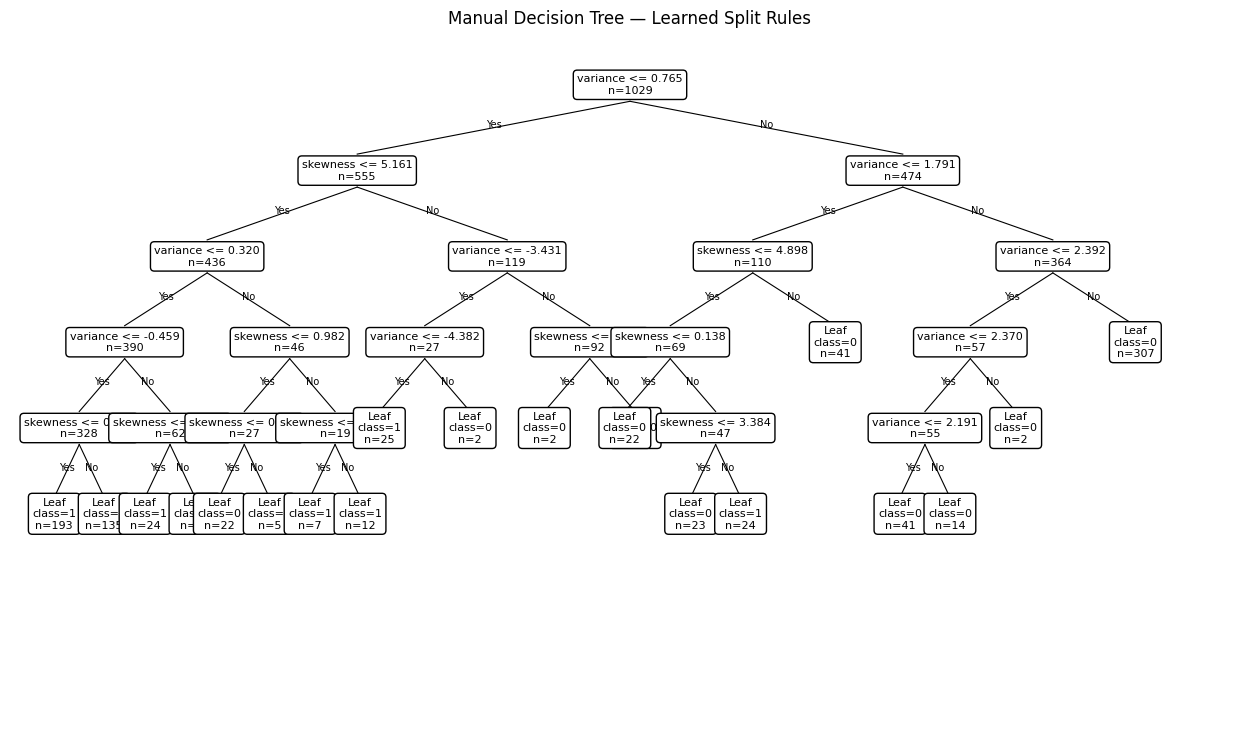

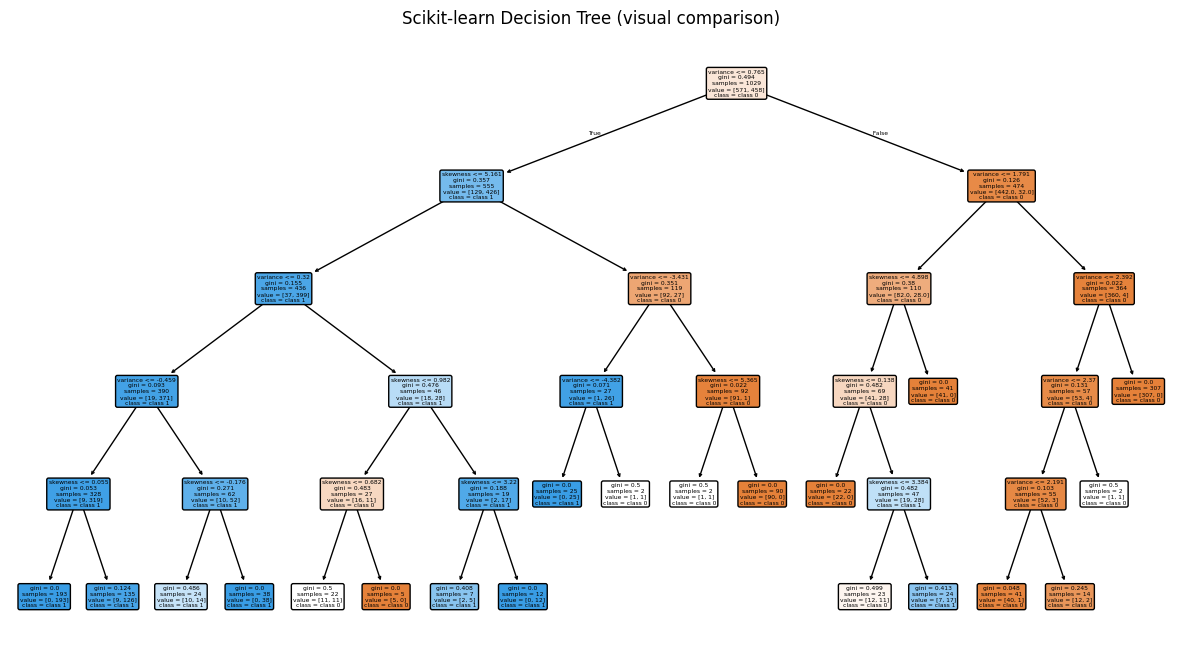

In [6]:
def draw_manual_tree(node, feature_names, ax, x=0.5, y=0.97, dx=0.22, dy=0.13):
    """Recursively draw the manual tree's split rules."""
    if node["feature"] is None:
        label = f"Leaf\nclass={node['prediction']}\nn={node['samples']}"
    else:
        label = f"{feature_names[node['feature']]} <= {node['threshold']:.3f}\nn={node['samples']}"
    ax.text(x, y, label, ha="center", va="center", fontsize=8,
            bbox=dict(boxstyle="round,pad=0.35", fc="white", ec="black"))
    if node["feature"] is not None:
        for child, child_x, edge_label in [(node["left"], x-dx, "Yes"), (node["right"], x+dx, "No")]:
            child_y = y - dy
            ax.plot([x, child_x], [y-0.025, child_y+0.025], color="black", linewidth=0.8)
            ax.text((x+child_x)/2, (y+child_y)/2, edge_label, fontsize=7, ha="center")
            draw_manual_tree(child, feature_names, ax, child_x, child_y, dx*0.55, dy)

fig, ax = plt.subplots(figsize=(16, 9))
ax.set_xlim(0, 1); ax.set_ylim(0, 1.05); ax.axis("off")
draw_manual_tree(manual_tree_2d.root_, ["variance", "skewness"], ax)
ax.set_title("Manual Decision Tree — Learned Split Rules")
plt.show()

plt.figure(figsize=(15, 8))
plot_tree(sk_tree_2d, feature_names=["variance", "skewness"],
          class_names=["class 0", "class 1"], filled=True, rounded=True)
plt.title("Scikit-learn Decision Tree (visual comparison)")
plt.show()

### A2. Criterion and maximum-depth settings

In [7]:
tree_experiments = []
for criterion in ["gini", "entropy"]:
    for depth in [2, 3, 5, 8, None]:
        model = ManualDecisionTree(criterion=criterion, max_depth=depth, min_samples_leaf=2)
        model.fit(X_train_2d, y_train)
        pred = model.predict(X_test_2d)
        tree_experiments.append({
            "implementation": "Manual", "criterion": criterion,
            "max_depth": str(depth), "accuracy": accuracy_score(y_test, pred),
            "nodes": None
        })
        sk_model = DecisionTreeClassifier(
            criterion=criterion, max_depth=depth, min_samples_leaf=2,
            random_state=RANDOM_STATE
        ).fit(X_train_2d, y_train)
        tree_experiments.append({
            "implementation": "Scikit-learn", "criterion": criterion,
            "max_depth": str(depth), "accuracy": accuracy_score(y_test, sk_model.predict(X_test_2d)),
            "nodes": sk_model.tree_.node_count
        })
display(pd.DataFrame(tree_experiments))

,implementation,criterion,max_depth,accuracy,nodes
0,Manual,gini,2,0.865889,NaN
1,Scikit-learn,gini,2,0.865889,7.0
2,Manual,gini,3,0.906706,NaN
3,Scikit-learn,gini,3,0.906706,15.0
4,Manual,gini,5,0.927114,NaN
5,Scikit-learn,gini,5,0.927114,39.0
6,Manual,gini,8,0.921283,NaN
7,Scikit-learn,gini,8,0.921283,85.0
8,Manual,gini,None,0.918367,NaN
9,Scikit-learn,gini,None,0.903790,115.0


# Part B — Linear Soft-Margin SVM from Scratch

The objective is

\[
J(w,b)=\frac{1}{2}\lVert w\rVert^2+
C\frac{1}{n}\sum_i\max(0,1-y_i(w^Tx_i+b)).
\]

Labels are mapped to -1 and +1. Features are standardized with training-set means and standard deviations only. The custom model uses batch subgradient descent on the regularized hinge-loss objective.

In [8]:
class ManualLinearSVM:
    """Linear soft-margin SVM trained with batch subgradient descent."""

    def __init__(self, C=1.0, learning_rate=0.01, n_iterations=3000):
        self.C = float(C)
        self.learning_rate = float(learning_rate)
        self.n_iterations = int(n_iterations)
        self.w = None
        self.b = 0.0
        self.mean_ = None
        self.scale_ = None
        self.loss_history = []

    def _fit_scale(self, X_values):
        self.mean_ = X_values.mean(axis=0)
        self.scale_ = X_values.std(axis=0)
        self.scale_[self.scale_ == 0] = 1.0
        return (X_values - self.mean_) / self.scale_

    def _transform(self, X_values):
        return (np.asarray(X_values, dtype=float) - self.mean_) / self.scale_

    def fit(self, X_values, y_values):
        X_values = np.asarray(X_values, dtype=float)
        y_values = np.asarray(y_values, dtype=float)
        if not np.all(np.isin(y_values, [-1, 1])):
            raise ValueError("Labels must be -1 and +1.")
        X_scaled = self._fit_scale(X_values)
        n_samples, n_features = X_scaled.shape
        self.w = np.zeros(n_features, dtype=float)
        self.b = 0.0
        self.loss_history = []

        for _ in range(self.n_iterations):
            margins = y_values * (X_scaled @ self.w + self.b)
            active = margins < 1.0
            grad_w = self.w - self.C * np.mean(
                (y_values[active, None] * X_scaled[active]), axis=0
            ) * (active.sum() / n_samples) if active.any() else self.w.copy()
            grad_b = -self.C * np.sum(y_values[active]) / n_samples if active.any() else 0.0
            self.w -= self.learning_rate * grad_w
            self.b -= self.learning_rate * grad_b
            new_margins = y_values * (X_scaled @ self.w + self.b)
            loss = 0.5 * np.dot(self.w, self.w) + self.C * np.maximum(0, 1-new_margins).mean()
            self.loss_history.append(float(loss))
        return self

    def decision_function(self, X_values):
        return self._transform(X_values) @ self.w + self.b

    def predict(self, X_values):
        return np.where(self.decision_function(X_values) >= 0, 1, -1)

Manual SVM 2D accuracy: 0.8717201166180758


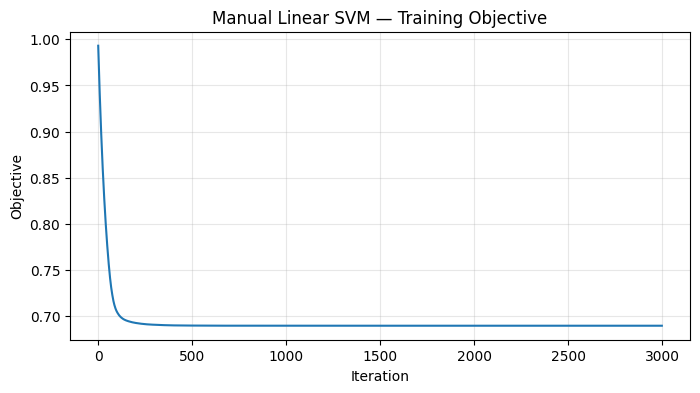

In [9]:
y_train_pm = np.where(y_train == 1, 1, -1)
y_test_pm = np.where(y_test == 1, 1, -1)

manual_svm_2d = ManualLinearSVM(C=1.0, learning_rate=0.01, n_iterations=3000)
manual_svm_2d.fit(X_train_2d, y_train_pm)
print("Manual SVM 2D accuracy:", accuracy_score(y_test_pm, manual_svm_2d.predict(X_test_2d)))

plt.figure(figsize=(8, 4))
plt.plot(manual_svm_2d.loss_history)
plt.xlabel("Iteration"); plt.ylabel("Objective")
plt.title("Manual Linear SVM — Training Objective")
plt.grid(alpha=0.3); plt.show()

C:\Users\daksh\AppData\Local\Temp\ipykernel_38888\3801142857.py:26: UserWarning: You passed a edgecolor/edgecolors ('k') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  plt.scatter(X_values[violations, 0], X_values[violations, 1],


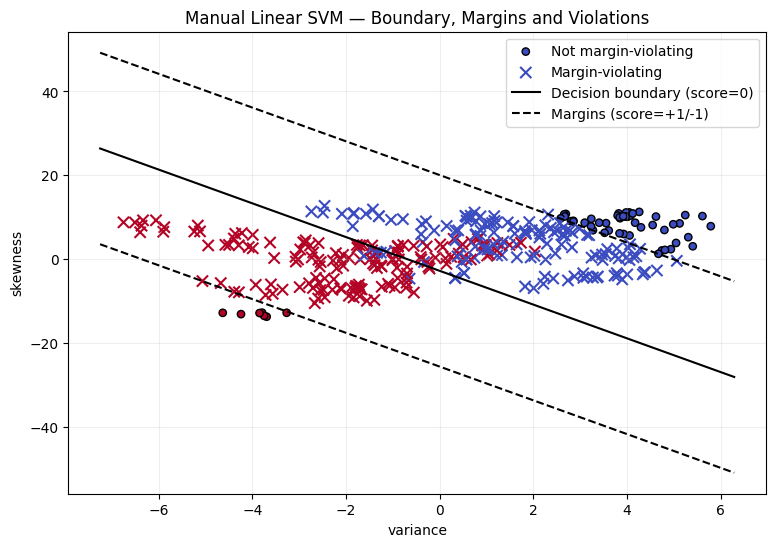

Margin-violating samples: 289 / 343
Scikit-learn linear SVM 2D accuracy: 0.8892128279883382


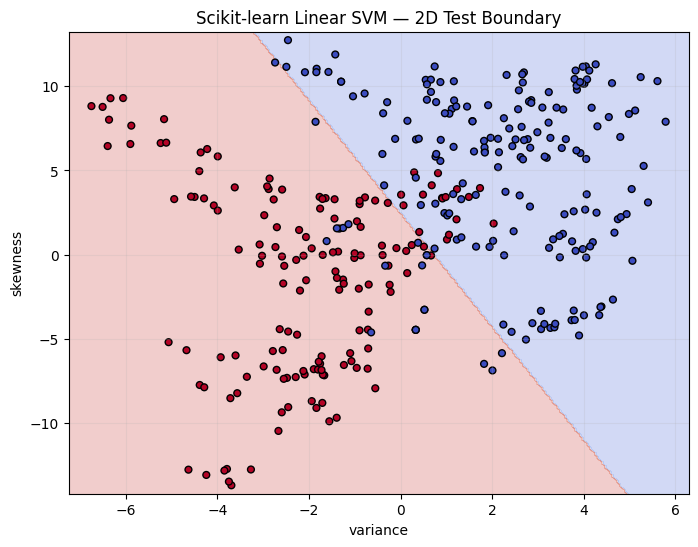

In [10]:
def plot_manual_svm_margins(model, X_values, y_original, title):
    """Plot the manual SVM decision line, margins, and margin violations."""
    X_values = np.asarray(X_values, dtype=float)
    y_pm = np.where(np.asarray(y_original) == 1, 1, -1)
    scores = model.decision_function(X_values)
    violations = y_pm * scores < 1.0

    x_min, x_max = X_values[:, 0].min()-0.5, X_values[:, 0].max()+0.5
    grid_x = np.linspace(x_min, x_max, 300)
    if abs(model.w[1]) < 1e-12:
        print("Cannot plot a finite y-value boundary: second weight is approximately zero.")
        return
    x_scaled = (grid_x - model.mean_[0]) / model.scale_[0]
    center_scaled = -(model.w[0]*x_scaled + model.b) / model.w[1]
    plus_scaled = (1-model.w[0]*x_scaled-model.b) / model.w[1]
    minus_scaled = (-1-model.w[0]*x_scaled-model.b) / model.w[1]
    center = center_scaled*model.scale_[1] + model.mean_[1]
    plus = plus_scaled*model.scale_[1] + model.mean_[1]
    minus = minus_scaled*model.scale_[1] + model.mean_[1]

    plt.figure(figsize=(9, 6))
    plt.scatter(X_values[~violations, 0], X_values[~violations, 1],
                c=y_pm[~violations], cmap="coolwarm", edgecolor="k", s=28,
                label="Not margin-violating")
    if violations.any():
        plt.scatter(X_values[violations, 0], X_values[violations, 1],
                    c=y_pm[violations], cmap="coolwarm", edgecolor="k",
                    marker="x", s=65, label="Margin-violating")
    plt.plot(grid_x, center, "k-", label="Decision boundary (score=0)")
    plt.plot(grid_x, plus, "k--", label="Margins (score=+1/-1)")
    plt.plot(grid_x, minus, "k--")
    plt.xlabel("variance"); plt.ylabel("skewness"); plt.title(title)
    plt.legend(); plt.grid(alpha=0.2); plt.show()
    print(f"Margin-violating samples: {violations.sum()} / {len(violations)}")

plot_manual_svm_margins(manual_svm_2d, X_test_2d, y_test,
                        "Manual Linear SVM — Boundary, Margins and Violations")

sk_svm_2d = make_pipeline(StandardScaler(), SVC(kernel="linear", C=1.0))
sk_svm_2d.fit(X_train_2d, y_train_pm)
print("Scikit-learn linear SVM 2D accuracy:",
      accuracy_score(y_test_pm, sk_svm_2d.predict(X_test_2d)))
plot_2d_boundary(sk_svm_2d, X_test_2d, y_test_pm,
                 "Scikit-learn Linear SVM — 2D Test Boundary")

### B1. Hyperparameter experiments
The table explores regularization strength `C`, learning rate, and number of iterations. Results depend on the dataset split and optimization settings.

In [11]:
svm_experiments = []
experiments = (
    [("C", value, value, 0.01, 3000) for value in [0.1, 1.0, 10.0]]
    + [("learning_rate", value, 1.0, value, 3000) for value in [0.001, 0.01, 0.05]]
    + [("iterations", value, 1.0, 0.01, value) for value in [500, 1500, 3000, 5000]]
)
for experiment, value, C_value, lr_value, iterations in experiments:
    model = ManualLinearSVM(C=C_value, learning_rate=lr_value, n_iterations=iterations)
    model.fit(X_train_2d, y_train_pm)
    svm_experiments.append({
        "experiment": experiment, "value": value,
        "accuracy": accuracy_score(y_test_pm, model.predict(X_test_2d)),
        "final_objective": model.loss_history[-1]
    })
display(pd.DataFrame(svm_experiments))

,experiment,value,accuracy,final_objective
0,C,0.100,0.556851,0.092913
1,C,1.000,0.871720,0.689814
2,C,10.000,0.892128,4.079420
3,learning_rate,0.001,0.886297,0.690865
4,learning_rate,0.010,0.871720,0.689814
5,learning_rate,0.050,0.871720,0.689814
6,iterations,500.000,0.877551,0.689981
7,iterations,1500.000,0.874636,0.689814
8,iterations,3000.000,0.871720,0.689814
9,iterations,5000.000,0.871720,0.689814


# Part C — Kernel SVM and Nonlinear Boundaries

A two-dimensional `make_moons` dataset is used to compare linear, polynomial, and RBF kernels. All models share the same train/test split.

In [12]:
X_moons, y_moons = make_moons(n_samples=700, noise=0.22, random_state=RANDOM_STATE)
X_moons_train, X_moons_test, y_moons_train, y_moons_test = train_test_split(
    X_moons, y_moons, test_size=0.25, random_state=RANDOM_STATE, stratify=y_moons
)

kernel_models = {
    "Linear kernel": make_pipeline(StandardScaler(), SVC(kernel="linear", C=1.0)),
    "Polynomial kernel (degree 3)": make_pipeline(
        StandardScaler(), SVC(kernel="poly", degree=3, C=1.0, gamma="scale")
    ),
    "RBF kernel": make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1.0, gamma="scale"))
}

kernel_rows = []
for name, model in kernel_models.items():
    model.fit(X_moons_train, y_moons_train)
    pred = model.predict(X_moons_test)
    kernel_rows.append({
        "model": name,
        "accuracy": accuracy_score(y_moons_test, pred),
        "precision": precision_score(y_moons_test, pred, zero_division=0),
        "recall": recall_score(y_moons_test, pred, zero_division=0),
        "f1": f1_score(y_moons_test, pred, zero_division=0)
    })
display(pd.DataFrame(kernel_rows))

,model,accuracy,precision,recall,f1
0,Linear kernel,0.897143,0.887640,0.908046,0.897727
1,Polynomial kernel (degree 3),0.885714,0.852632,0.931034,0.890110
2,RBF kernel,0.937143,0.922222,0.954023,0.937853


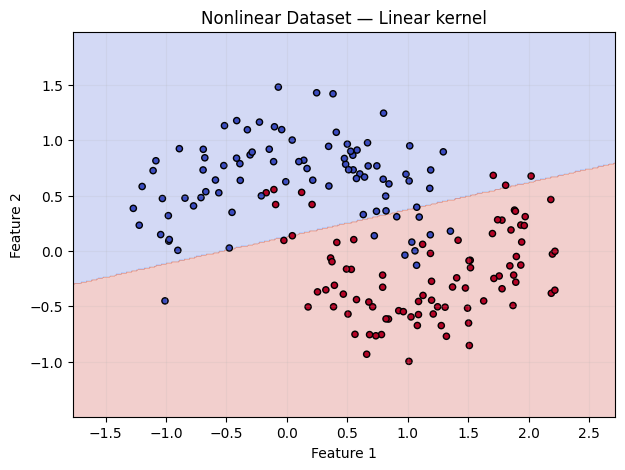

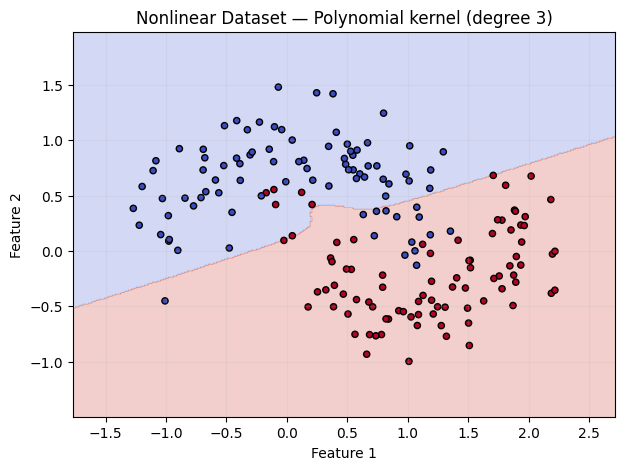

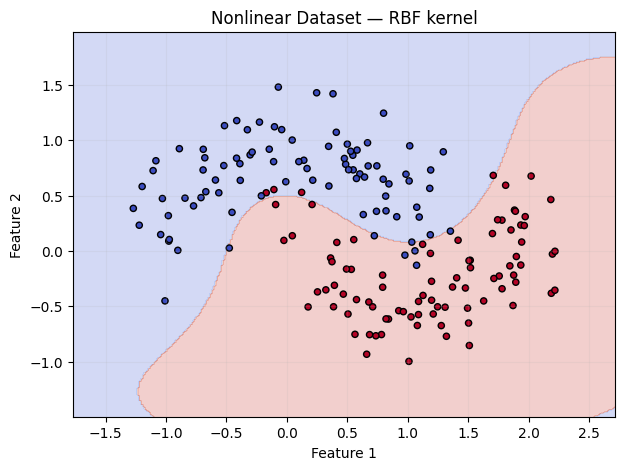

In [13]:
def plot_estimator_boundary(model, X_values, y_values, title, grid_points=300):
    x_min, x_max = X_values[:, 0].min()-0.5, X_values[:, 0].max()+0.5
    y_min, y_max = X_values[:, 1].min()-0.5, X_values[:, 1].max()+0.5
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, grid_points),
                         np.linspace(y_min, y_max, grid_points))
    zz = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    plt.figure(figsize=(7, 5))
    plt.contourf(xx, yy, zz, alpha=0.25, cmap="coolwarm")
    plt.scatter(X_values[:, 0], X_values[:, 1], c=y_values,
                cmap="coolwarm", edgecolor="k", s=20)
    plt.title(title); plt.xlabel("Feature 1"); plt.ylabel("Feature 2")
    plt.grid(alpha=0.15); plt.show()

for model_name, model in kernel_models.items():
    plot_estimator_boundary(model, X_moons_test, y_moons_test,
                            f"Nonlinear Dataset — {model_name}")

**Interpretation:** A linear kernel creates a straight boundary. Polynomial and RBF kernels can create curved boundaries. RBF models local distance-based similarity; polynomial kernels represent polynomial feature interactions. Discuss the actual scores shown above rather than assuming one kernel always wins.

# Part D — Final Four-Feature Comparison

All banknote models in this section use the same split and all four features. Training and prediction times are measured separately; timings vary by machine and runtime conditions.

In [14]:
def metrics_dict(y_true, y_pred):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0)
    }


def timed_evaluation(name, model, X_tr, y_tr, X_te, y_te,
                     train_label_transform=None, pred_label_transform=None):
    train_labels = train_label_transform(y_tr) if train_label_transform else y_tr
    start = time.perf_counter()
    model.fit(X_tr, train_labels)
    train_time = time.perf_counter() - start

    start = time.perf_counter()
    pred = model.predict(X_te)
    predict_time = time.perf_counter() - start
    if pred_label_transform:
        pred = pred_label_transform(pred)

    row = {
        "model": name,
        **metrics_dict(y_te, pred),
        "training_time_seconds": train_time,
        "prediction_time_seconds": predict_time
    }
    return row, model


to_pm_one = lambda labels: np.where(np.asarray(labels) == 1, 1, -1)
from_pm_one = lambda labels: np.where(np.asarray(labels) == 1, 1, 0)

final_rows, final_models = [], {}

models_to_run = [
    ("Manual Decision Tree (4 features)",
     ManualDecisionTree(criterion="gini", max_depth=8, min_samples_leaf=2),
     None, None),
    ("Scikit-learn Decision Tree (4 features)",
     DecisionTreeClassifier(criterion="gini", max_depth=8, min_samples_leaf=2,
                            random_state=RANDOM_STATE),
     None, None),
    ("Manual Linear SVM (4 features)",
     ManualLinearSVM(C=1.0, learning_rate=0.01, n_iterations=4000),
     to_pm_one, from_pm_one),
    ("Scikit-learn Linear SVM (4 features)",
     make_pipeline(StandardScaler(), SVC(kernel="linear", C=1.0, random_state=RANDOM_STATE)),
     to_pm_one, from_pm_one),
    ("Scikit-learn RBF SVM (4 features)",
     make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1.0, gamma="scale", random_state=RANDOM_STATE)),
     None, None)
]

for name, model, label_transform, pred_transform in models_to_run:
    row, fitted = timed_evaluation(
        name, model, X_train, y_train, X_test, y_test,
        train_label_transform=label_transform,
        pred_label_transform=pred_transform
    )
    final_rows.append(row)
    final_models[name] = fitted

final_results = pd.DataFrame(final_rows).sort_values("f1", ascending=False).reset_index(drop=True)
display(final_results)

,model,accuracy,precision,recall,f1,training_time_seconds,prediction_time_seconds
0,Scikit-learn RBF SVM (4 features),1.000000,1.000000,1.000000,1.000000,0.004665,0.002232
1,Scikit-learn Decision Tree (4 features),0.982507,0.986667,0.973684,0.980132,0.002541,0.000173
2,Scikit-learn Linear SVM (4 features),0.976676,0.950000,1.000000,0.974359,0.006950,0.000798
3,Manual Decision Tree (4 features),0.973761,0.986395,0.953947,0.969900,0.901864,0.000361
4,Manual Linear SVM (4 features),0.892128,0.952756,0.796053,0.867384,0.381876,0.000039


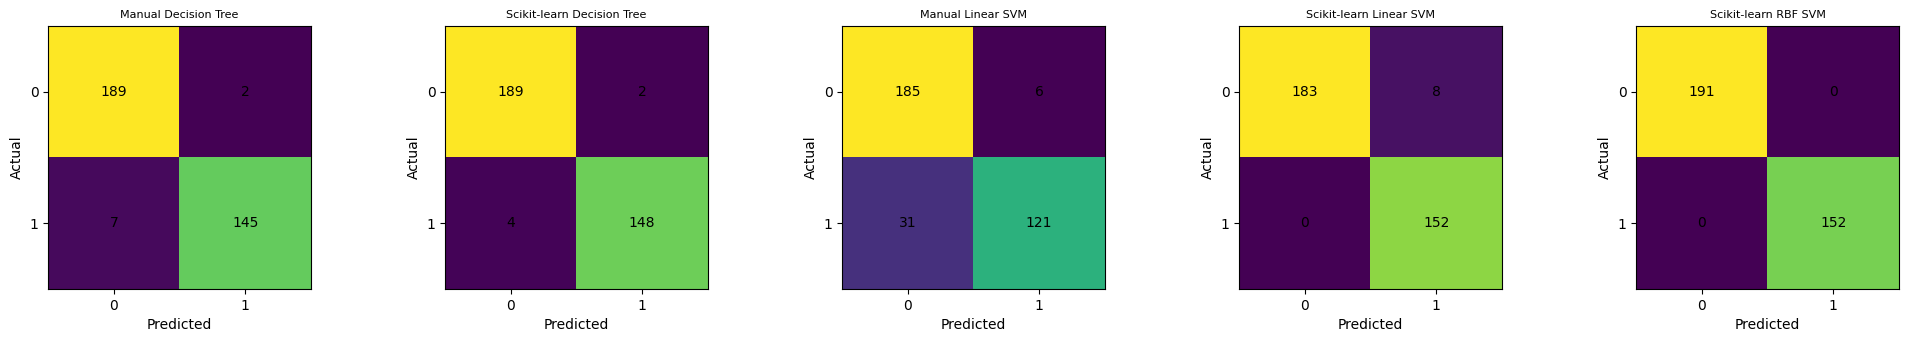

In [15]:
fig, axes = plt.subplots(1, len(final_models), figsize=(4 * len(final_models), 3.5))
if len(final_models) == 1:
    axes = [axes]

for ax, (name, model) in zip(axes, final_models.items()):
    pred = model.predict(X_test)
    if "Linear SVM" in name:
        pred = from_pm_one(pred)
    cm = confusion_matrix(y_test, pred, labels=[0, 1])
    ax.imshow(cm)
    ax.set_title(name.replace(" (4 features)", ""), fontsize=8)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_xticks([0, 1], labels=["0", "1"])
    ax.set_yticks([0, 1], labels=["0", "1"])
    for (i, j), value in np.ndenumerate(cm):
        ax.text(j, i, str(value), ha="center", va="center")
plt.tight_layout()
plt.show()